In [ ]:
!pip install split-folders

Copying files: 14 files [01:43,  7.38s/ files]


In [ ]:
import splitfolders
from google.colab import drive
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
INPUT_DIR = '/content/drive/MyDrive/Skripsi/Dataset/'
OUTPUT_DIR = '/content/drive/MyDrive/Skripsi/Dataset Split'

splitfolders.ratio(INPUT_DIR, output=OUTPUT_DIR, seed=42, ratio=(.8, .2), group_prefix=None)

print("Proses pengacakan dan pemisahan folder selesai!")



Copying files: 0 files [00:00, ? files/s]

Copying files: 5 files [00:00, 42.21 files/s]

Copying files: 10 files [00:00, 33.77 files/s]

Copying files: 15 files [00:00, 37.62 files/s]

Copying files: 20 files [00:00, 41.53 files/s]

Copying files: 25 files [00:00, 42.60 files/s]

Copying files: 31 files [00:00, 44.58 files/s]

Copying files: 36 files [00:02, 10.54 files/s]

Copying files: 41 files [00:02, 13.85 files/s]

Copying files: 45 files [00:02, 12.25 files/s]

Copying files: 50 files [00:02, 15.86 files/s]

Copying files: 54 files [00:04,  7.30 files/s]
Copying files: 19 files [00:12, 40.98 files/s]

Copying files: 58 files [00:05,  5.11 files/s]

Copying files: 62 files [00:05,  6.76 files/s]

Copying files: 67 files [00:05,  9.52 files/s]

Copying files: 71 files [00:06,  6.27 files/s]

Copying files: 77 files [00:06,  9.33 files/s]

Copying files: 81 files [00:08,  5.61 files/s]

Copying files: 87 files [00:08,  8.26 files/s]

Copying files: 93 files [00:08, 11.51 files/s

Proses pengacakan dan pemisahan folder selesai!


In [ ]:
TRAIN_DIR = '/content/drive/MyDrive/Skripsi/Dataset Split/train'
VAL_DIR = '/content/drive/MyDrive/Skripsi/Dataset Split/val'

val_datagen = ImageDataGenerator(rescale=1./255)

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(150, 150),
    batch_size=16,
    class_mode='categorical'
)

validation_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(150, 150),
    batch_size=16,
    class_mode='categorical',
    shuffle=False # Tetap False agar Confusion Matrix berurutan
)

Found 480 images belonging to 6 classes.
Found 120 images belonging to 6 classes.


In [ ]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(6, activation='softmax')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    train_generator,
    epochs=20,
    validation_data=validation_generator
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.2021 - loss: 1.8780 - val_accuracy: 0.1667 - val_loss: 1.7892
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.1500 - loss: 1.7948 - val_accuracy: 0.2000 - val_loss: 1.7827
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 46s 2s/step - accuracy: 0.2354 - loss: 1.7758 - val_accuracy: 0.2583 - val_loss: 1.7309
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.2500 - loss: 1.7379 - val_accuracy: 0.3083 - val_loss: 1.6631
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.3250 - loss: 1.6462 - val_accuracy: 0.3083 - val_loss: 1.6865
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.3521 - loss: 1.5988 - val_accuracy: 0.4083 - val_loss: 1.5251
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.3833 - loss: 1.5753 - val_accuracy: 0.4000 - val_loss: 1.4747
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.3667 - loss: 1.5403 - val_accuracy: 0.4917 - val_loss:

8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step
              precision    recall  f1-score   support

Adallyn bag        0.48      0.50      0.49        20
  Bucket Bag       0.68      0.65      0.67        20
   Calla bag       0.55      0.80      0.65        20
  Iveyt shoe       0.73      0.55      0.63        20
  Midori Bag       0.73      0.40      0.52        20
 lando shoe        0.64      0.80      0.71        20

    accuracy                           0.62       120
   macro avg       0.64      0.62      0.61       120
weighted avg       0.64      0.62      0.61       120



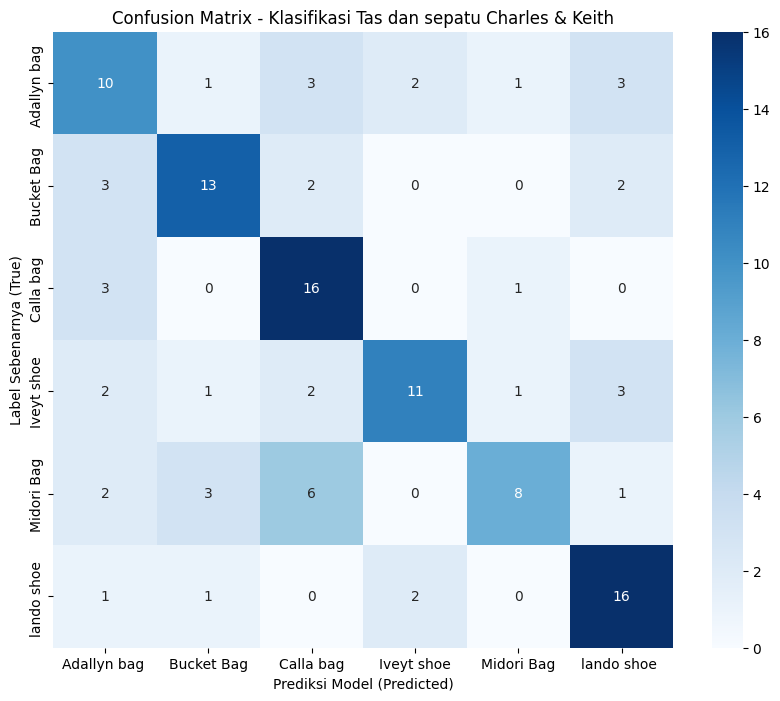

In [ ]:

Y_pred = model.predict(validation_generator)

y_pred = np.argmax(Y_pred, axis=1)

y_true = validation_generator.classes

class_names = list(validation_generator.class_indices.keys())


print(classification_report(y_true, y_pred, target_names=class_names))


cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Confusion Matrix - Klasifikasi Tas dan sepatu Charles & Keith')
plt.ylabel('Label Sebenarnya (True)')
plt.xlabel('Prediksi Model (Predicted)')
plt.show()

In [ ]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']



In [ ]:
epochs_range = range(1, 31)

plt.figure(figsize=(14, 5))

<Figure size 1400x500 with 0 Axes>

<Figure size 1400x500 with 0 Axes>

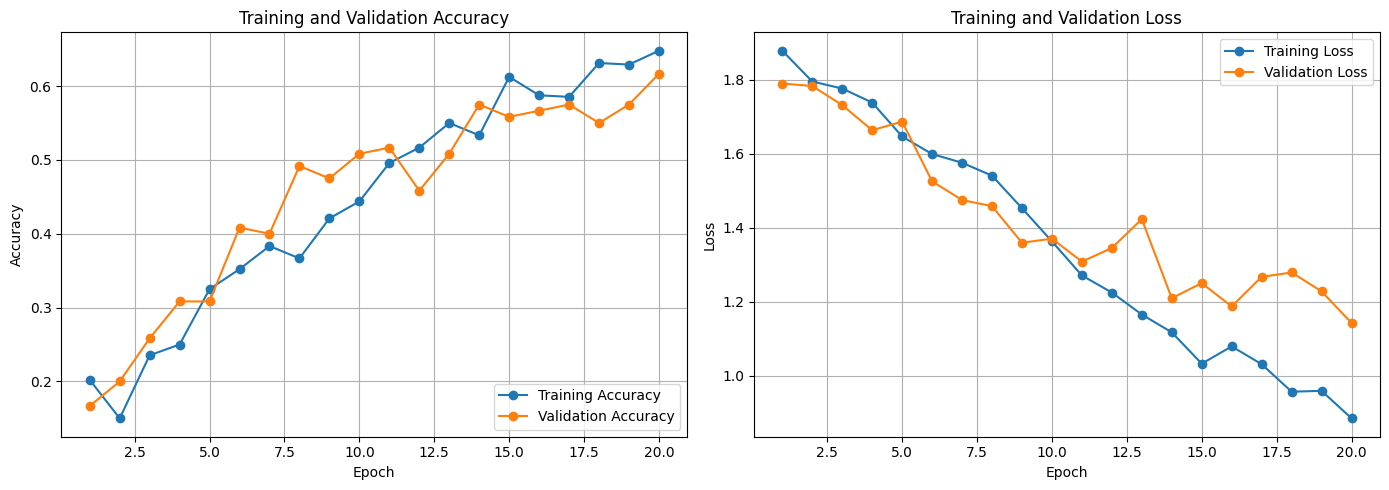

In [ ]:
import matplotlib.pyplot as plt

# Ambil data dari history
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

# SOLUSI: Buat epochs_range secara otomatis mengikuti jumlah riwayat 'acc'
epochs_range = range(1, len(acc) + 1)

# --- Lanjut ke kode plotting kamu ---
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)

plt.tight_layout()
plt.show()